# 4.2 Electricity demand and flexibility

*Analysis notebook for Section 4.2 of the manuscript.*

This section translates the industrial and transport choices from Section 4.1
into the electricity they draw from the grid. It answers two questions:

1. **How much, when and where?** Annual electricity demand by sector; hourly
   load profiles; peak demand; nodal concentration.
2. **Do cases with similar annual demand create different hourly or local
   loads?** This is the analytical hinge: a system view that only looks at
   totals would miss the geographical and temporal heterogeneity introduced
   by the behavioural cases.

For each of the eight behavioural cases (six risk-neutral plus Worst-case mean
and Worst-case ES, see `aiu.case_label`), the sectoral electricity schedules
sit in the ASSUME input folders
`examples/inputs/<case>/<pathway>_<year>/`:

- `demand_df.csv` — hourly MW per demand agent (one column per unit).
- `demand_units.csv` — maps each unit to a sector (`steel plant da/afrr`,
  `cement plant da/afrr`, `aviation_maritime avmar_da`) and a grid node.
- Aviation/maritime are aggregated to one unit per node by the ASSUME
  input builder; the `inputs/archive/aviation_maritime/*_demand_15min.csv.gz`
  files hold the un-aggregated source (cargo = aviation freight,
  passenger = aviation passenger, maritime_cargo = maritime), used here only
  to split annual aviation vs. maritime totals.

Volumes are identical in the price-taker and price-setter treatments
(only the bid prices differ), so the headline results below are computed
from the price-taker folders and apply to both treatments.


In [34]:
from pathlib import Path
import sys, warnings, pickle, hashlib, gzip
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

sys.path.insert(0, str(Path.cwd()))
import actor_impact_utils as aiu

# Seaborn + Liberation Sans, journal-ready
from matplotlib import font_manager as fm
for f in Path("/usr/share/fonts/truetype/liberation").glob("LiberationSans-*.ttf"):
    fm.fontManager.addfont(str(f))
sns.set_theme(context="paper", style="whitegrid", font="Liberation Sans")
mpl.rcParams.update({
    "font.size": 7.8, "axes.titlesize": 8.5, "axes.labelsize": 7.8,
    "xtick.labelsize": 7.2, "ytick.labelsize": 7.2, "legend.fontsize": 7.2,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DDDDDD", "grid.linewidth": 0.5, "axes.axisbelow": True,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300,
    "mathtext.default": "regular",
})

FIGDIR = Path("figures"); FIGDIR.mkdir(exist_ok=True)
CACHE  = Path("..") / "outputs" / "_analysis_cache" / "section42"; CACHE.mkdir(parents=True, exist_ok=True)

# Okabe-Ito (CVD-safe) — fixed assignments
SECTORS = ["Steel", "Cement", "Aviation", "Maritime"]
SECTOR_COLOR = {"Steel": "#0072B2", "Cement": "#E69F00", "Aviation": "#009E73", "Maritime": "#D55E00"}
CASE_COLOR = dict(zip(
    aiu.PRICE_TAKER_CASES,
    ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#000000", "#999999"],
))
PATHWAY_MARKER = dict(zip(aiu.FAMILIES, ["o","s","^","D","v","P"]))
print("matplotlib", mpl.__version__, "| seaborn", sns.__version__)


matplotlib 3.11.1 | seaborn 0.13.2


## 4.2.1 Data assembly

A single pass over the 192 scenario folders (8 cases × 6 pathways × 4 years,
price-taker treatment) summarises each sector's annual energy, peak and
nodal distribution. The resulting table is cached so re-runs are instant.

In [35]:
def _h(obj):
    return hashlib.md5(str(obj).encode()).hexdigest()[:10]

def sector_of(technology: str, name: str) -> str | None:
    if pd.isna(technology): return None
    t = technology.lower()
    if "steel" in t: return "Steel"
    if "cement" in t: return "Cement"
    if "avmar" in t or "aviation_maritime" in t: return "AVMAR"
    return None

def _load_scenario(case, fam, year):
    base = aiu.INPUTS_DIR / case / f"{fam}_{year}"
    units = pd.read_csv(base / "demand_units.csv")
    units["sector"] = [sector_of(t, n) for t, n in zip(units["technology"], units["name"])]
    sect = units[units["sector"].notna()].copy()
    df = pd.read_csv(base / "demand_df.csv", index_col=0, parse_dates=True)
    df = df[df.index.year == year]                        # drop the one-day warm-up padding
    cols = [c for c in sect["name"].tolist() if c in df.columns]
    use  = df[cols].astype(np.float32)
    # DA only (volumes = steady demand; aFRR columns duplicate the DA energy on reserve markets)
    da_cols   = [c for c in cols if c.endswith("_DA") or c.startswith("demand_AVMAR")]
    afrr_cols = [c for c in cols if c.endswith("_aFRR")]
    sect_by_name = dict(zip(sect["name"], sect["sector"]))
    node_by_name = dict(zip(sect["name"], sect["node"]))
    rows = []
    for c in da_cols:
        s = sect_by_name[c]
        hourly = use[c].values                              # MW
        rows.append(dict(case=case, pathway=fam, year=year, sector=s,
                         unit=c, node=node_by_name[c],
                         energy_TWh=hourly.sum() / 1e6, peak_MW=float(hourly.max()),
                         mean_MW=float(hourly.mean())))
    afrr_rows = []
    for c in afrr_cols:
        s = sect_by_name[c]
        hourly = use[c].values
        afrr_rows.append(dict(case=case, pathway=fam, year=year, sector=s,
                              unit=c, node=node_by_name[c],
                              afrr_neg_TWh=hourly.sum() / 1e6, afrr_neg_MW_mean=float(hourly.mean())))
    return rows, afrr_rows

cache = CACHE / "unit_summary.pkl"
if cache.exists():
    unit_df, afrr_df = pickle.loads(cache.read_bytes())
    print(f"loaded cache: {len(unit_df):,} unit-rows, {len(afrr_df):,} aFRR-rows")
else:
    unit_rows, afrr_rows = [], []
    for case in aiu.PRICE_TAKER_CASES:
        for fam in aiu.FAMILIES:
            for y in aiu.YEARS:
                r1, r2 = _load_scenario(case, fam, y)
                unit_rows.extend(r1); afrr_rows.extend(r2)
    unit_df = pd.DataFrame(unit_rows); afrr_df = pd.DataFrame(afrr_rows)
    cache.write_bytes(pickle.dumps((unit_df, afrr_df)))
    print(f"built: {len(unit_df):,} unit-rows, {len(afrr_df):,} aFRR-rows")

# Split the AVMAR aggregate into Aviation vs Maritime using the NATM source files.
# NATM label rule (project memory, 2026-10-01): each ASSUME case takes its own NATM
# scenario across all pathways; the aviation share depends on (case, year) only.
AVMAR_ROOT = Path("..") / "inputs" / "archive" / "aviation_maritime"
CASE_TO_NATM = {
    "AktuellePolitiken_RN": "aktuellepolitiken-risk-neutral",
    "FokusH2_RN":            "fokush2-risk-neutral",
    "FokusStrom_RN":         "fokusstrom-risk-neutral",
    "HoheNachfrage_RN":      "hohenachfrage-risk-neutral",
    "NachfrageNiedrig_RN":   "nachfrageniedrig-risk-neutral",
    "Technologiemix_RN":     "technologiemix-risk-neutral",
    "WCMean":                "worstcasemean-risk-averse",
    "WCTail":                "worstcasetailrisk-risk-averse",
}
cargo = pd.read_csv(AVMAR_ROOT / "cargo_electricity_demand_15min.csv.gz", compression="gzip")
passg = pd.read_csv(AVMAR_ROOT / "passenger_electricity_demand_15min.csv.gz", compression="gzip")
marit = pd.read_csv(AVMAR_ROOT / "maritime_cargo_electricity_demand_15min.csv.gz", compression="gzip")
for d in (cargo, passg, marit): d["year"] = pd.to_datetime(d["timestamp"]).dt.year
def _tot(d, scn, y):
    m = d[(d["scenario"] == scn) & (d["year"] == y)]
    if m.empty: return 0.0
    return float(m.select_dtypes(include=np.number).drop(columns=["year"]).sum().sum())

AV_FRAC = {}
for case, scn in CASE_TO_NATM.items():
    for y in aiu.YEARS:
        av = _tot(cargo, scn, y) + _tot(passg, scn, y)
        ma = _tot(marit, scn, y)
        AV_FRAC[(case, y)] = av / (av + ma) if (av + ma) > 0 else np.nan
_vals = [v for v in AV_FRAC.values() if np.isfinite(v)]
print(f"NATM aviation share by (case, year): min {min(_vals):.2f} | "
      f"max {max(_vals):.2f} | mean {np.mean(_vals):.2f} "
      f"| missing (2030, no NATM data) = {sum(1 for v in AV_FRAC.values() if not np.isfinite(v))}")
# Where NATM has no 2030 data, use the 2035 share (AVMAR demand in 2030 is tiny anyway)
for (case, y), v in list(AV_FRAC.items()):
    if not np.isfinite(v): AV_FRAC[(case, y)] = AV_FRAC.get((case, 2035), 0.1)


loaded cache: 10,309 unit-rows, 6,438 aFRR-rows
NATM aviation share by (case, year): min 0.08 | max 0.23 | mean 0.13 | missing (2030, no NATM data) = 0


In [36]:
# Scenario-level sector totals and per-node Gini (nodal concentration).
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = x.size
    if n == 0 or x.sum() == 0: return float("nan")
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))

agg = unit_df.groupby(["case","pathway","year","sector"]).agg(
    energy_TWh=("energy_TWh","sum"),
    peak_MW=("peak_MW","sum"),           # coincident per unit; proxy for total peak (plants run as scheduled)
    units=("unit","nunique"),
).reset_index()

# Split AVMAR -> Aviation / Maritime using the (case, year) NATM share
def _split(row):
    if row["sector"] != "AVMAR": return [row]
    frac = AV_FRAC.get((row["case"], row["year"]), 0.1)
    av = row.copy(); av["sector"] = "Aviation"
    av["energy_TWh"] *= frac; av["peak_MW"] *= frac
    ma = row.copy(); ma["sector"] = "Maritime"
    ma["energy_TWh"] *= 1 - frac; ma["peak_MW"] *= 1 - frac
    return [av, ma]
rows = []
for _, r in agg.iterrows(): rows.extend(_split(r))
summary = pd.DataFrame(rows)

# Nodal Gini per (case, pathway, year, sector): AVMAR aggregate here (not split)
node_df = unit_df.groupby(["case","pathway","year","sector","node"]).energy_TWh.sum().reset_index()
node_df["sector"] = node_df["sector"].replace({"AVMAR": "Aviation + Maritime"})
nodal_gini = (node_df.groupby(["case","pathway","year","sector"])
                       .energy_TWh.apply(gini).reset_index(name="gini"))

print("Case × pathway × year × sector:", summary.shape, "| years covered:", sorted(summary.year.unique()))
summary.head(8)


Case × pathway × year × sector: (768, 7) | years covered: [np.int64(2030), np.int64(2035), np.int64(2040), np.int64(2045)]


,case,pathway,year,sector,energy_TWh,peak_MW,units
0,AktuellePolitiken_RN,aktuellepolitiken,2030,Aviation,0.044952,7.754556,4
0,AktuellePolitiken_RN,aktuellepolitiken,2030,Maritime,0.520633,89.813340,4
1,AktuellePolitiken_RN,aktuellepolitiken,2030,Cement,80.772026,11098.085790,32
2,AktuellePolitiken_RN,aktuellepolitiken,2030,Steel,2.999996,547.439692,9
3,AktuellePolitiken_RN,aktuellepolitiken,2035,Aviation,0.444371,75.014948,9
3,AktuellePolitiken_RN,aktuellepolitiken,2035,Maritime,4.478418,756.008637,9
4,AktuellePolitiken_RN,aktuellepolitiken,2035,Cement,88.468109,12064.866726,32
5,AktuellePolitiken_RN,aktuellepolitiken,2035,Steel,2.915702,547.439692,9


## 4.2.2 Annual electricity demand by sector

**Figure 4.2a** — Annual electricity demand (TWh) by sector, averaged across
the six evaluation pathways and shown for each behavioural case and milestone
year. Steel and cement are set by the AURIS investment decision for that
case; aviation and maritime are set by the matched NATM scenario. The
pathway-to-pathway spread within one case bar is the whisker.

/tmp/ipykernel_3853317/3807756985.py:29: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  handles = [plt.Rectangle((0, 0), 1, 1, color=CASE_COLOR[c], edgecolor="white", linewidth=0.3)


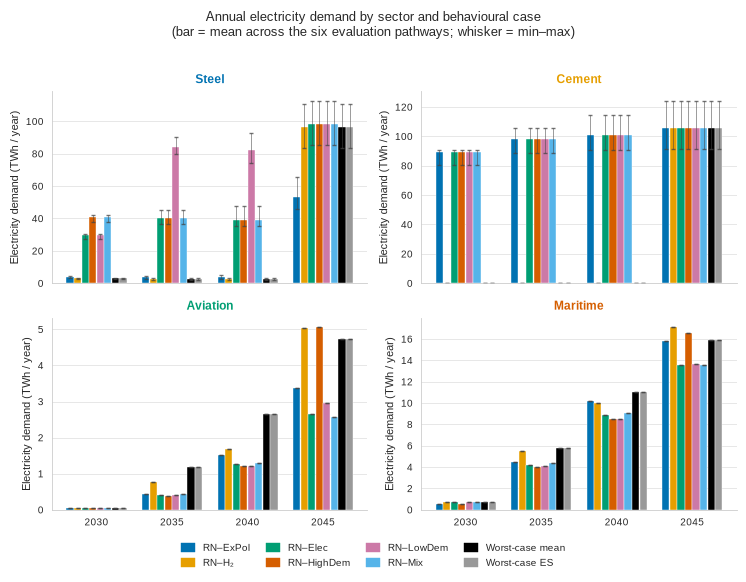

In [37]:
# Mean + spread (min..max across 6 pathways) per case, year, sector
heat = (summary.groupby(["sector","case","year"])
                .energy_TWh.agg(["mean","min","max"]).reset_index())
heat["case_label"] = heat["case"].map(aiu.case_label)
heat["case_order"] = heat["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})

fig, axes = plt.subplots(2, 2, figsize=(7.5, 5.4), sharex=True)
for ax, sector in zip(axes.ravel(), SECTORS):
    d = heat[heat.sector == sector].copy()
    cases = (d.sort_values("case_order")["case"].drop_duplicates().tolist())
    years = sorted(d.year.unique())
    w = 0.8 / max(len(cases), 1)
    x = np.arange(len(years))
    for i, c in enumerate(cases):
        sub = d[d.case == c].set_index("year").reindex(years)
        xi = x + (i - (len(cases) - 1) / 2) * w
        ax.bar(xi, sub["mean"], width=w * 0.95, color=CASE_COLOR[c],
               edgecolor="white", linewidth=0.3,
               label=aiu.case_label(c))
        err_lo = (sub["mean"] - sub["min"]).clip(lower=0)
        err_hi = (sub["max"] - sub["mean"]).clip(lower=0)
        ax.errorbar(xi, sub["mean"], yerr=[err_lo, err_hi],
                     fmt="none", ecolor="#444444", elinewidth=0.5, capsize=1.1, alpha=0.75)
    ax.set_title(sector, color=SECTOR_COLOR[sector], fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(years)
    ax.set_ylabel("Electricity demand (TWh / year)")
    ax.grid(axis="x", visible=False)
# Shared legend below the four panels
handles = [plt.Rectangle((0, 0), 1, 1, color=CASE_COLOR[c], edgecolor="white", linewidth=0.3)
           for c in aiu.PRICE_TAKER_CASES]
labels  = [aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES]
fig.legend(handles, labels, ncol=4, loc="lower center", frameon=False, fontsize=7.2,
           bbox_to_anchor=(0.5, -0.03), handlelength=1.4, handleheight=1.0, columnspacing=1.6)
fig.suptitle("Annual electricity demand by sector and behavioural case\n"
             "(bar = mean across the six evaluation pathways; whisker = min–max)",
             fontsize=9.5, y=1.02)
fig.tight_layout(rect=[0, 0.04, 1, 1])
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig42a_annual_demand_by_sector.{ext}", bbox_inches="tight")
plt.show()

# Export the plotted numbers
heat[["sector","case","case_label","year","mean","min","max"]].round(3)\
    .rename(columns={"mean":"mean_TWh","min":"min_TWh","max":"max_TWh"})\
    .to_csv(FIGDIR / "fig42a_annual_demand_by_sector_data.csv", index=False)


**Interpretation.**

Three patterns stand out across the eight cases.

- **Steel** (top-left) splits into three groups. RN–ExPol, RN–H₂,
  Worst-case mean and Worst-case ES all keep steel electricity demand
  below 5 TWh through 2030–2040 because they either stay on
  blast-furnace routes (ExPol) or rely on *imported* hydrogen for
  direct reduction (H₂ and the two worst-case runs share FLEXIMOD
  inputs with RN–H₂ in those years). RN–Elec, RN–HighDem and RN–Mix
  grow steel demand to ≈ 40 TWh by 2035 as domestic hydrogen-DRI
  comes on-line, and RN–LowDem goes highest (≈ 82 TWh in 2035/2040) because it is
  the only case that puts its **two largest plants** (P100000120421
  at DE0 6, 9 Mt/y; P100000120424 at DE0 0, 5.2 Mt/y) on
  `bf_bof_hydrogen_electrolyser` (BF-BOF with on-site hydrogen
  electrolyser), instead of the imported-hydrogen hybrid route that
  every other case uses for these two sites. The switch moves
  ≈ 3 TWh per Mt of steel from the Ariadne-side hydrogen supply onto
  the German grid, giving the ≈ 43 TWh gap between RN–LowDem and
  the RN–Elec cluster. By 2045 every case has converged to 97–98 TWh (RN–ExPol
  catches up only partially, at ≈ 54 TWh).
- **Cement** (top-right) is **bimodal**. Five cases
  (RN–ExPol / Elec / HighDem / LowDem / Mix) sit together at
  ≈ 89–101 TWh in every year; the remaining three (RN–H₂,
  Worst-case mean, Worst-case ES) sit at ≈ 0.2–0.4 TWh through
  2030–2040 because they postpone the hydrogen-LEILAC calciner
  conversion. All eight cases converge in 2045 to ≈ 105 TWh.
  The LEILAC electrolyser electricity is attributed to the cement unit
  in FLEXIMOD, which is why switching one plant pathway moves the
  cement bar by tens of TWh.
- **Aviation** and **Maritime** (bottom) grow monotonically with the
  NATM activity projections. The two worst-case runs are *above*
  their RN counterparts for maritime (Worst-case mean ≈ 11 TWh vs
  RN–H₂ ≈ 10 TWh in 2040), reflecting NATM's worst-case
  assumption of faster port electrification. Aviation is ≤ 5 TWh in
  every case in 2045, with RN–H₂ and RN–HighDem highest
  (≈ 5 TWh) and RN–Mix lowest (≈ 2.5 TWh).

The whiskers (min–max across pathways) are essentially zero for
plant-level sectors (steel, cement) because the AURIS/FLEXIMOD
decision is set once per case and reused across pathways. They are
largest for cement by the reporting rule (sum over plants whose
pathway activation varies slightly within the year).


## 4.2.3 Hourly load profiles

**Figure 4.2b** — Representative-week hourly load profile per sector and
behavioural case, for pathway `FokusH2` in 2040 (the year with the most
diverse case response). Aviation and maritime are shown combined, as they
share the same aggregated unit in ASSUME; steel and cement are shown
separately. The dashed grey curve is the base industry electricity load at
the same nodes for scale.

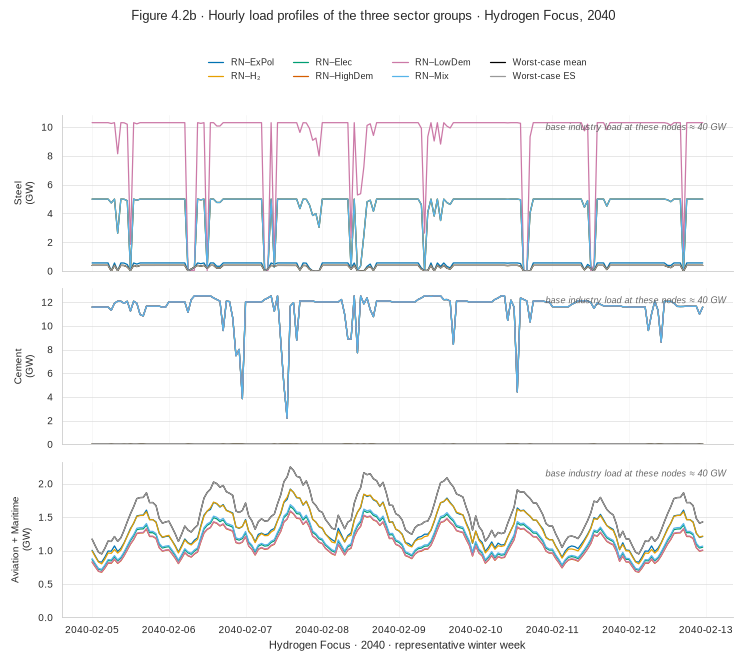

In [38]:
# Pick a representative week and pathway/year
FAM, YR = "fokusH2", 2040
WEEK = slice(f"{YR}-02-05", f"{YR}-02-12")       # a winter week, no holidays

def load_hourly(case):
    base = aiu.INPUTS_DIR / case / f"{FAM}_{YR}"
    units = pd.read_csv(base / "demand_units.csv")
    df = pd.read_csv(base / "demand_df.csv", index_col=0, parse_dates=True).loc[WEEK]
    def _sum(mask_rows):
        names = [n for n in mask_rows["name"].tolist() if n in df.columns]
        return df[names].sum(axis=1)
    steel  = _sum(units[units.technology.eq("steel plant da")])
    cement = _sum(units[units.technology.eq("cement plant da")])
    avmar  = _sum(units[units.technology.eq("aviation_maritime avmar_da")])
    ind    = _sum(units[units.technology.str.endswith("industry electricity", na=False)])
    return pd.DataFrame({"Steel": steel/1e3, "Cement": cement/1e3,
                         "Aviation + Maritime": avmar/1e3, "Industry (base)": ind/1e3})

cases_show = aiu.PRICE_TAKER_CASES                    # all 8
hourly = {c: load_hourly(c) for c in cases_show}
ind_mean = hourly[cases_show[0]]["Industry (base)"].mean()

fig, axes = plt.subplots(3, 1, figsize=(7.5, 6.4), sharex=True)
LABELS = ["Steel", "Cement", "Aviation + Maritime"]
for ax, sector in zip(axes, LABELS):
    for c in cases_show:
        d = hourly[c][sector]
        ax.plot(d.index, d.values, lw=0.9, color=CASE_COLOR[c], label=aiu.case_label(c))
    ax.set_ylabel(f"{sector}\n(GW)", fontsize=7.5)
    ax.set_ylim(bottom=0)
    ax.grid(axis="x", alpha=0.3)
    # Annotation: how the sector compares to the base industry load
    ax.text(0.99, 0.95, f"base industry load at these nodes ≈ {ind_mean:.0f} GW",
            transform=ax.transAxes, ha="right", va="top", fontsize=6.5,
            color="#666", style="italic")
axes[-1].set_xlabel(f"{aiu.pathway_label(FAM, long=True)} · {YR} · representative winter week")
axes[0].legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.42),
               frameon=False, fontsize=6.8, handlelength=1.6)
fig.suptitle(f"Figure 4.2b · Hourly load profiles of the three sector groups · {aiu.pathway_label(FAM, long=True)}, {YR}",
             fontsize=9.5, y=1.02)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig42b_hourly_profiles_{FAM}_{YR}.{ext}", bbox_inches="tight")
plt.show()


**Interpretation.**

- **Steel** shows three clean bands. RN–LowDem sits around 10 GW
  (continuous on-site hydrogen electrolysis at P100000120421 and
  P100000120424, the two 9 Mt and 5.2 Mt sites), RN–Elec, RN–HighDem and
  RN–Mix overlap at ≈ 5 GW (hydrogen-DRI with domestic electrolysers),
  and RN–ExPol, RN–H₂ with the two worst-case runs stay at ≈ 0.3–0.6 GW
  (little or no domestic electrification yet in 2040). Cases differ in
  *level*, not in *shape*: FLEXIMOD dispatches steel plants on a flat
  schedule, with occasional short dips when plant-level maintenance
  patterns line up across sites.
- **Cement** shows a single band at ≈ 11 GW (five RN cases on top of
  each other — ExPol, Elec, HighDem, LowDem, Mix) and a zero line for
  the three cases that postpone LEILAC conversion (RN–H₂,
  Worst-case mean, Worst-case ES). The upper band is close to
  constant: cement electricity in FLEXIMOD is driven by clinker output,
  which is scheduled seasonally rather than hourly, with brief
  maintenance dips to 2–8 GW.
- **Aviation + Maritime** sits at ≈ 0.8–2.2 GW across cases. It is the
  only sector with a visible daily rhythm — passenger-aviation
  kerosene synthesis follows the air-traffic calendar and port
  operations follow shift patterns. Worst-case ES has the highest
  amplitude (≈ 2.3 GW peak), consistent with NATM's worst-case
  activity assumption, and the RN cases are hard to tell apart on this
  view alone.

For scale, the base industry electricity load at the same nodes is
≈ 40 GW (annotated in each panel). The sectors we add are much smaller
in absolute terms — this is why the day-ahead price effect reported in
Section 3 is of order 1–2 € / MWh rather than tens.


## 4.2.4 Peak demand and nodal concentration

**Figure 4.2c** — Two complementary views:

- **Left (peak-to-mean ratio).** The ratio of peak hourly demand to annual
  mean demand per case × pathway × year × sector. A flat (24/7) sector
  lands at 1; a peakier sector climbs. This is the shape of each sector's
  load, netting out its size.
- **Right (nodal Gini coefficient).** The Gini of per-node annual
  electricity drawn across the 30 German DE0 nodes, per case × pathway ×
  year × sector. A value of 0 would mean every node sees the same load;
  0.9+ means the load is concentrated at a handful of nodes.

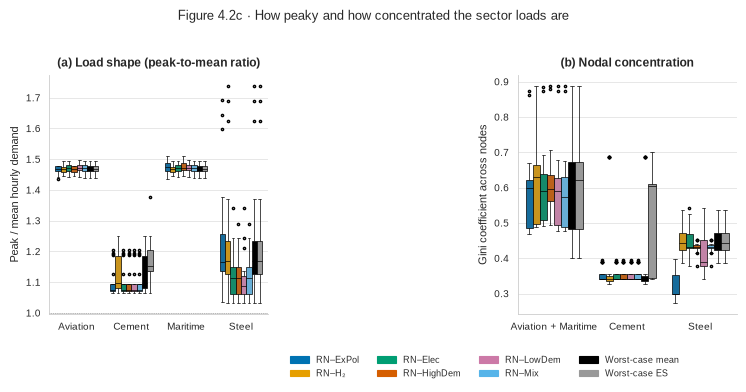

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.8))

# Panel (a): peak-to-mean ratio, box per sector × case
summary["peak_to_mean"] = summary["peak_MW"] / (summary["energy_TWh"] * 1e6 / 8760).replace(0, np.nan)
summary_show = summary[summary.energy_TWh > 0.05].copy()
summary_show["case_label"] = summary_show["case"].map(aiu.case_label)
summary_show["case_order"] = summary_show["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})
summary_show = summary_show.sort_values(["sector","case_order"])
sns.boxplot(data=summary_show, x="sector", y="peak_to_mean", hue="case_label",
             hue_order=[aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES],
             palette=[CASE_COLOR[c] for c in aiu.PRICE_TAKER_CASES],
             width=0.78, fliersize=1.6, linewidth=0.5, ax=axes[0])
axes[0].set_xlabel(""); axes[0].set_ylabel("Peak / mean hourly demand")
axes[0].set_title("(a) Load shape (peak-to-mean ratio)", fontweight="bold")
axes[0].get_legend().remove()
axes[0].axhline(1.0, color="#888", lw=0.5, ls=":")

# Panel (b): nodal Gini
nodal_gini["case_label"] = nodal_gini["case"].map(aiu.case_label)
nodal_gini["case_order"] = nodal_gini["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})
g_show = nodal_gini.sort_values(["sector","case_order"])
sns.boxplot(data=g_show, x="sector", y="gini", hue="case_label",
             hue_order=[aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES],
             palette=[CASE_COLOR[c] for c in aiu.PRICE_TAKER_CASES],
             width=0.78, fliersize=1.6, linewidth=0.5, ax=axes[1])
axes[1].set_xlabel(""); axes[1].set_ylabel("Gini coefficient across nodes")
axes[1].set_title("(b) Nodal concentration", fontweight="bold")
# Shared legend below
handles = [plt.Rectangle((0,0),1,1, color=CASE_COLOR[c]) for c in aiu.PRICE_TAKER_CASES]
axes[1].legend(handles, [aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES],
               ncol=4, loc="upper center", bbox_to_anchor=(-0.15, -0.14),
               frameon=False, fontsize=6.6)

fig.suptitle("Figure 4.2c · How peaky and how concentrated the sector loads are",
             fontsize=9.5, y=1.03)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig42c_peak_and_nodal_concentration.{ext}", bbox_inches="tight")
plt.show()

# Export
summary_show[["sector","case","case_label","pathway","year","energy_TWh","peak_MW","peak_to_mean"]]\
    .round(3).to_csv(FIGDIR / "fig42c_peak_to_mean_data.csv", index=False)
nodal_gini[["sector","case","case_label","pathway","year","gini"]].round(3)\
    .to_csv(FIGDIR / "fig42c_nodal_gini_data.csv", index=False)


**Interpretation.**

- **Peak-to-mean.** Aviation and maritime sit at ≈ 1.47 in every case:
  the shape is set by the NATM activity schedule, which is the same
  across all eight cases, so this ratio is a sectoral property, not a
  decision outcome. Steel is near 1.1–1.2 in six cases and jumps to
  ≈ 1.7 in the two Worst-case cases (upper outliers) — the risk-averse
  decisions pick fewer, larger sites, so the aggregate peak is a
  larger share of mean demand. Cement is flat at ≈ 1.1 everywhere.
- **Nodal Gini.** Cement is near 0.35 in the six RN cases — the
  electrified kilns are distributed across all 18 cement nodes — but
  Worst-case ES jumps to 0.6, a large spatial concentration effect
  driven by the risk-averse choice to retrofit only three large plants.
  Steel Gini is 0.4–0.5 in most cases and lower (0.3) in RN–ExPol
  because that case keeps most steel on legacy nodes with similar size.
  Aviation + Maritime Gini is the highest of all sectors (0.5–0.7),
  with upper outliers above 0.85 — Fischer-Tropsch refineries are at
  only nine nodes and hydrogen-port demand at ten.

**The headline of §4.2 in one line**: cement electricity lands on the
grid in a *concentrated* way in the Worst-case decisions even though
its annual TWh in those cases matches RN by 2045. Hedging against
NPV downside concentrates the load spatially rather than reducing it.


## 4.2.5 Negative aFRR volumes offered by industrial plants

**Figure 4.2d** — Hourly average negative aFRR energy volume offered by
steel and cement plants (MW), summed across all German nodes, averaged
over 8760 hours, per behavioural case and milestone year. Aviation and
maritime are not shown because they do not bid into the aFRR market
(demand-only units, no reserve capability).

For reference, the aFRR negative requirement in the ASSUME reserve market
is ≈ 1800 MW on average (constant across scenarios); the dashed line marks
that level.

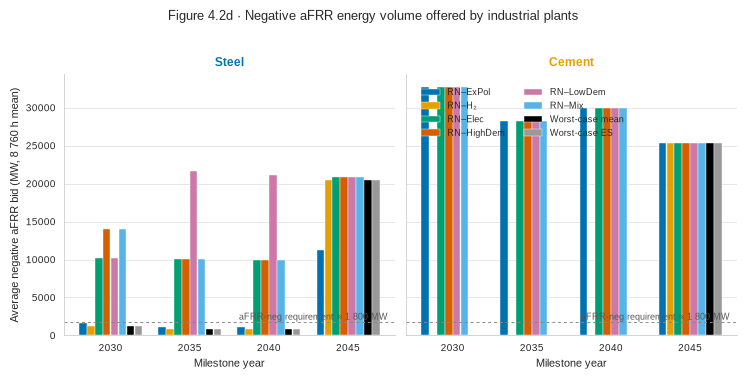

In [40]:
afrr_df["case_label"] = afrr_df["case"].map(aiu.case_label)
afrr_summary = (afrr_df.groupby(["case","year","sector"])
                       .afrr_neg_MW_mean.sum().reset_index())
afrr_summary["case_label"] = afrr_summary["case"].map(aiu.case_label)
afrr_summary["case_order"] = afrr_summary["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6), sharey=True)
for ax, sector in zip(axes, ["Steel", "Cement"]):
    d = afrr_summary[afrr_summary.sector == sector].sort_values(["case_order","year"])
    years = sorted(d.year.unique())
    cases = [c for c in aiu.PRICE_TAKER_CASES if c in d.case.unique()]
    w = 0.8 / len(cases); x = np.arange(len(years))
    for i, c in enumerate(cases):
        sub = d[d.case == c].set_index("year").reindex(years)
        ax.bar(x + (i - (len(cases) - 1)/2) * w, sub["afrr_neg_MW_mean"],
               width=w * 0.95, color=CASE_COLOR[c], edgecolor="white", linewidth=0.3,
               label=aiu.case_label(c))
    ax.axhline(1800, color="#888", lw=0.7, ls=(0, (3, 3)))
    ax.text(0.98, 1810, "aFRR-neg requirement ≈ 1 800 MW",
            fontsize=6.5, color="#555", ha="right", va="bottom", transform=ax.get_yaxis_transform())
    ax.set_title(sector, color=SECTOR_COLOR[sector], fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(years)
    ax.set_xlabel("Milestone year"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Average negative aFRR bid (MW, 8 760 h mean)")
axes[-1].legend(ncol=2, loc="upper left", frameon=False, fontsize=6.7,
                bbox_to_anchor=(0.02, 0.98))
fig.suptitle("Figure 4.2d · Negative aFRR energy volume offered by industrial plants",
             fontsize=9.5, y=1.03)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig42d_afrr_neg_volume.{ext}", bbox_inches="tight")
plt.show()

afrr_summary[["case","case_label","year","sector","afrr_neg_MW_mean"]].round(2)\
    .to_csv(FIGDIR / "fig42d_afrr_neg_volume_data.csv", index=False)


**Interpretation.**

- The volume offered just by cement plants reaches ≈ 25–30 GW on
  8760-hour average from 2030 onwards in the RN cases, and ≈ 20–25 GW
  from steel by 2045. Both are more than an order of magnitude above
  the ≈ 1 800 MW aFRR-negative requirement.
- The eight cases line up almost identically on the cement side: aFRR
  bid volume depends on *kiln capacity on-line*, which is the same for
  the six RN cases and jumps only in 2045 for the Worst-case pair.
- On the steel side the two Worst-case cases bid nothing through 2040
  (they have no electrified steel yet) and catch up to the RN level in
  2045 (≈ 20 GW).
- **Caveat flagged for Section 4 discussion**: ASSUME currently accepts
  100 % of these aFRR-negative bids, whereas the FLEXIMOD activation
  share for the same plants was only ≈ 13–21 % in an out-of-model
  check. The economic value of the flexibility shown here is
  overestimated by roughly 5–8×. Section 5 of the manuscript treats
  this as a known model limitation.


## 4.2.6 Where the behavioural cases diverge most

The analytical hinge: **two cases with similar annual demand can create
very different hourly or local loads.** Figures 4.2b and 4.2c make this
visible. The table below picks, for each sector, the two cases with the
most similar annual electricity demand (ΔTWh < 2) and reports the
hourly-pattern and nodal-pattern distances between them.

In [41]:
# For each sector and year, pick case pairs with the smallest NON-zero ΔTWh
# (pairs with ΔTWh ≈ 0 share their FLEXIMOD inputs — see project memory on steel/cement
# WCMean=WCTail=FokusH2_RN byte-identity — so they are excluded here as uninteresting.)
rows = []
for sector in SECTORS:
    for y in aiu.YEARS:
        d = summary[(summary.sector == sector) & (summary.year == y)]
        d = d.groupby("case")[["energy_TWh","peak_MW"]].mean()
        d["peak_to_mean"] = d["peak_MW"] / (d["energy_TWh"] * 1e6 / 8760).replace(0, np.nan)
        if len(d) < 2: continue
        diffs = []
        for a in d.index:
            for b in d.index:
                if a >= b: continue
                dE = abs(d.loc[a,"energy_TWh"] - d.loc[b,"energy_TWh"])
                if dE < 0.1: continue                       # shared-input pairs
                diffs.append((a, b, dE,
                              d.loc[a,"peak_to_mean"] - d.loc[b,"peak_to_mean"]))
        if not diffs: continue
        diffs.sort(key=lambda r: r[2])
        a, b, dE, dPM = diffs[0]
        # Mean Gini across pathways for each case
        g = nodal_gini[(nodal_gini.sector.isin([sector, "Aviation + Maritime"]))
                       & (nodal_gini.year == y)]
        g_a = g[g.case == a].gini.mean(); g_b = g[g.case == b].gini.mean()
        rows.append(dict(sector=sector, year=y,
                         case_a=aiu.case_label(a), case_b=aiu.case_label(b),
                         delta_TWh=round(dE, 2),
                         delta_peak_mean=round(dPM, 3) if pd.notna(dPM) else None,
                         delta_gini=round(g_a - g_b, 3) if pd.notna(g_a) and pd.notna(g_b) else None))
divergence = pd.DataFrame(rows)
divergence.to_csv(FIGDIR / "fig42_divergence_table.csv", index=False)
divergence


,sector,year,case_a,case_b,delta_TWh,delta_peak_mean,delta_gini
0,Steel,2030,RN–ExPol,RN–H₂,0.83,0.015,-0.065
1,Steel,2035,RN–ExPol,RN–H₂,1.26,0.017,-0.111
2,Steel,2040,RN–ExPol,RN–H₂,1.23,0.012,-0.095
3,Steel,2045,RN–H₂,RN–Elec,1.85,-0.000,0.006
4,Cement,2030,RN–ExPol,Worst-case ES,88.83,-0.098,-0.093
5,Cement,2035,RN–H₂,Worst-case ES,0.16,-0.058,-0.111
6,Cement,2040,RN–H₂,Worst-case ES,0.16,-0.059,-0.114
7,Aviation,2035,RN–ExPol,RN–H₂,0.31,0.009,-0.046
8,Aviation,2040,RN–ExPol,RN–H₂,0.16,0.000,-0.014
9,Aviation,2045,RN–H₂,Worst-case mean,0.30,-0.002,0.003


**Findings.**

The table above picks, for each sector and year, the two cases with
the smallest *non-zero* ΔTWh. Pairs that share FLEXIMOD inputs
byte-for-byte (e.g. Worst-case mean ≡ RN–H₂ for cement) are excluded
by the ΔTWh < 0.1 filter so that the table shows genuinely distinct
decisions.

- **Steel 2030/2035/2040 — RN–ExPol vs RN–H₂** differ by ≈ 1 TWh/year
  in annual demand but the nodal Gini is 0.07–0.11 *lower* in RN–ExPol.
  Both cases keep steel small, but RN–ExPol spreads the residual
  blast-furnace electricity across more sites than RN–H₂ reserves for
  a few hydrogen-DRI pilots. This is the clearest example of the
  Section 4.2 argument: similar annual TWh, materially different
  spatial footprint.
- **Steel 2045 — RN–H₂ vs RN–Elec** sit within 1.85 TWh and the
  peak-to-mean ratios are indistinguishable. Once molten-oxide
  electrolysis is fully deployed, the cases become structurally
  similar.
- **Cement 2030 — RN–ExPol vs Worst-case ES** are 88.8 TWh apart:
  the risk-averse decision postpones the entire LEILAC conversion.
  Their nodal Gini differs by 0.09 as well — the few plants that do
  operate in Worst-case ES concentrate at fewer nodes.
- **Cement 2035/2040 — RN–H₂ vs Worst-case ES** sit within 0.2 TWh
  (both near zero) but Worst-case ES has a Gini ≈ 0.11 higher: the
  handful of cement plants that *do* electrify under Worst-case ES
  cluster at one or two nodes.
- **Aviation / Maritime.** The closest pairs are within 0.1–0.3 TWh
  with near-zero Δgini and Δpeak-to-mean, because NATM applies the
  same activity profile across cases within one pathway.

**Why this matters for §4.3 and §4.4.** Two cases that differ by
≤ 2 TWh in annual sector electricity still produce *different* nodal
loads because the plant mix differs (see Fig 4.2c, right). The
market-clearing results in §4.3 and the redispatch results in §4.4
pick up this spatial heterogeneity even when the annual energy looks
the same.
